# Blinkit Analysis
Sales performance, customer satisfaction and inventory distribution, following the business requirement in `Blinkit_Analysis.pptx`.

**Put `blinkit_data.csv` in the same folder as this notebook** (or change `PATH` below).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.express as px

PATH = "C:\\Users\\user\\Downloads\\Blinkit\\blinkit_data.csv"
df = pd.read_csv(PATH, encoding="utf-8-sig")
print(df.shape)
df.head()

(8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## 1. Data cleaning
`Item Fat Content` has inconsistent labels (`LF`, `low fat`, `reg`). Standardise them to **Low Fat** / **Regular**.

In [2]:
print(df["Item Fat Content"].value_counts(), "\n")
df["Item Fat Content"] = df["Item Fat Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})
print(df["Item Fat Content"].value_counts())
print("\nMissing values:\n", df.isna().sum()[lambda s: s > 0])  # Item Weight only; not used in any KPI

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64 

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Missing values:
 Item Weight    1463
dtype: int64


## 2. KPIs
- **Total Sales** – sum of `Sales`
- **Average Sales** – mean `Sales` per item record
- **Number of Items** – count of item records
- **Average Rating** – mean `Rating`

In [3]:
def kpis(g):
    return pd.Series({"Total Sales": g["Sales"].sum(), "Average Sales": g["Sales"].mean(),
                      "Number of Items": len(g), "Average Rating": g["Rating"].mean()})

overall = kpis(df)
print(f"Total Sales     : ${overall['Total Sales']:,.0f}")
print(f"Average Sales   : ${overall['Average Sales']:,.2f}")
print(f"Number of Items : {overall['Number of Items']:,.0f}")
print(f"Average Rating  : {overall['Average Rating']:.2f}")

def summary(col):
    """Total Sales + the other three KPIs, grouped by `col`."""
    return df.groupby(col).apply(kpis, include_groups=False).round(2)

fmt = {"Total Sales": "${:,.0f}", "Average Sales": "${:,.2f}", "Number of Items": "{:,.0f}", "Average Rating": "{:.2f}"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREEN, YELLOW = "#0c831f", "#f8cb46"
PAL = ["#0c831f", "#f8cb46", "#2b7de9", "#e8574a", "#8a5cd0"]

Total Sales     : $1,201,681
Average Sales   : $140.99
Number of Items : 8,523
Average Rating  : 3.97


## 3. Charts
### 3.1 Total Sales by Fat Content (donut)

,Total Sales,Average Sales,Number of Items,Average Rating
Item Fat Content,,,,
Low Fat,"$776,320",$140.71,"5,517",3.97
Regular,"$425,362",$141.50,"3,006",3.97


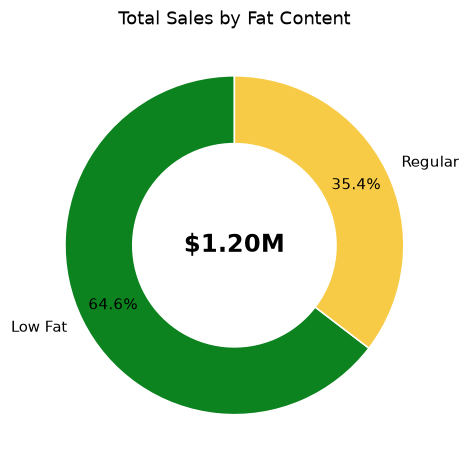

In [4]:
t = summary("Item Fat Content")
display(t.style.format(fmt))
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(t["Total Sales"], labels=t.index, colors=PAL, autopct="%1.1f%%", startangle=90,
       wedgeprops=dict(width=0.4, edgecolor="white"), pctdistance=0.8)
ax.text(0, 0, f"${t['Total Sales'].sum()/1e6:.2f}M", ha="center", va="center", fontsize=16, weight="bold")
ax.set_title("Total Sales by Fat Content"); plt.show()

### 3.2 Total Sales by Item Type (bar)

,Total Sales,Average Sales,Number of Items,Average Rating
Item Type,,,,
Fruits and Vegetables,"$178,124",$144.58,"1,232",3.96
Snack Foods,"$175,434",$146.19,"1,200",3.95
Household,"$135,977",$149.42,910,4.00
Frozen Foods,"$118,559",$138.50,856,3.97
Dairy,"$101,276",$148.50,682,3.97
Canned,"$90,707",$139.76,649,3.99
Baking Goods,"$81,895",$126.38,648,3.98
Health and Hygiene,"$68,026",$130.82,520,3.99
Meat,"$59,450",$139.88,425,4.02


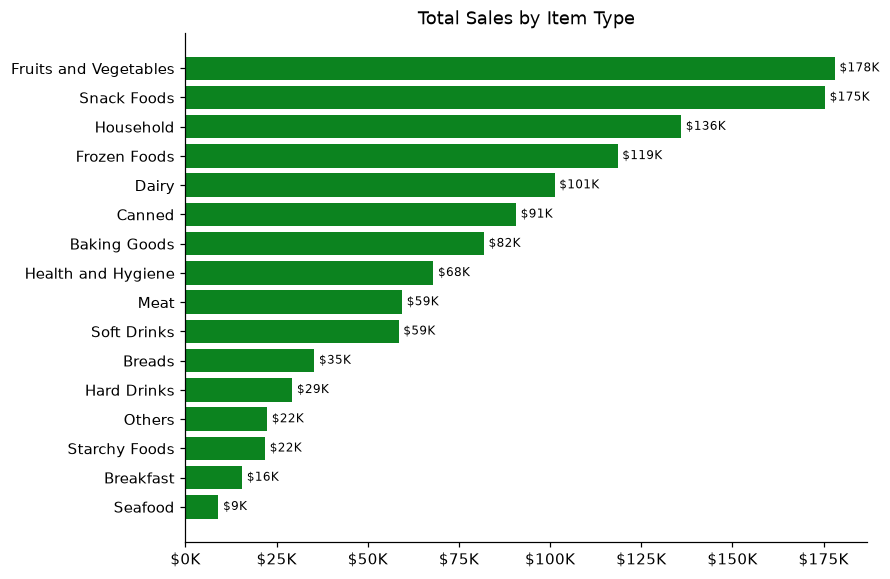

In [5]:
t = summary("Item Type").sort_values("Total Sales")
display(t.sort_values("Total Sales", ascending=False).style.format(fmt))
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(t.index, t["Total Sales"], color=GREEN)
ax.bar_label(bars, labels=[f"${v/1000:,.0f}K" for v in t["Total Sales"]], padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_title("Total Sales by Item Type"); plt.show()

### 3.3 Fat Content by Outlet for Total Sales (stacked column)

Item Fat Content,Low Fat,Regular
Outlet Identifier,,
OUT010,"$51,786","$26,346"
OUT013,"$86,402","$45,407"
OUT017,"$82,947","$46,157"
OUT018,"$84,845","$46,633"
OUT019,"$48,029","$25,779"
OUT027,"$83,774","$46,940"
OUT035,"$86,483","$46,621"
OUT045,"$85,035","$45,908"
OUT046,"$84,603","$47,510"


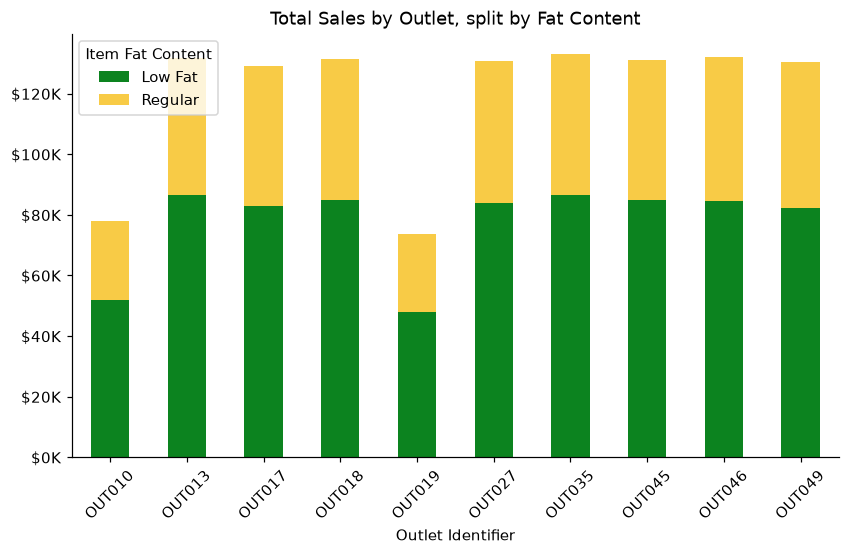

In [6]:
p = df.pivot_table(index="Outlet Identifier", columns="Item Fat Content", values="Sales", aggfunc="sum")
display(p.round(0).style.format("${:,.0f}"))
# other KPIs per outlet x fat content
display(df.groupby(["Outlet Identifier", "Item Fat Content"]).apply(kpis, include_groups=False).round(2).style.format(fmt))
ax = p.plot(kind="bar", stacked=True, color=PAL[:2], figsize=(9, 5), rot=45)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_title("Total Sales by Outlet, split by Fat Content"); plt.show()

### 3.4 Total Sales by Outlet Establishment Year (line)

,Total Sales,Average Sales,Number of Items,Average Rating
Outlet Establishment Year,,,,
1998,204522.260000,139.800000,1463.000000,3.970000
2000,131809.020000,141.430000,932.000000,3.950000
2010,132113.370000,142.060000,930.000000,3.960000
2011,78131.560000,140.780000,555.000000,3.980000
2012,130476.860000,140.300000,930.000000,3.990000
2015,130942.780000,140.950000,929.000000,3.960000
2017,133103.910000,143.120000,930.000000,3.940000
2020,129103.960000,139.420000,926.000000,3.980000
2022,131477.770000,141.680000,928.000000,3.970000


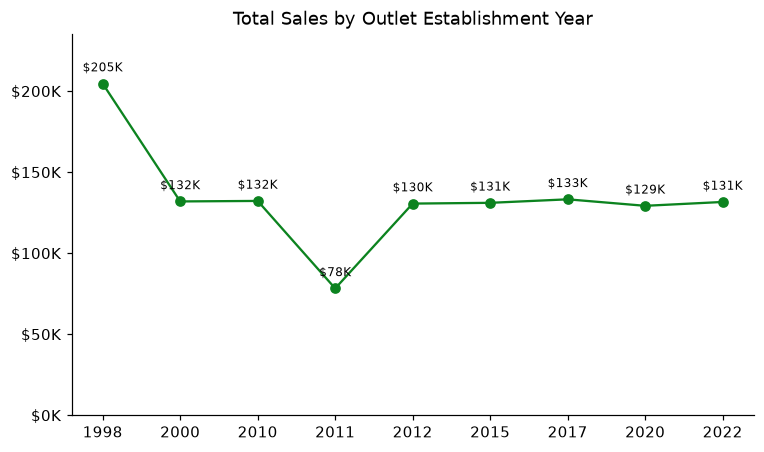

In [7]:
t = summary("Outlet Establishment Year")
display(t.style.format(fmt, precision=2).format({"Outlet Establishment Year": "{}"}, na_rep=""))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t.index.astype(str), t["Total Sales"], marker="o", color=GREEN)
for x, y in zip(t.index.astype(str), t["Total Sales"]):
    ax.annotate(f"${y/1000:,.0f}K", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_ylim(0, t["Total Sales"].max() * 1.15)
ax.set_title("Total Sales by Outlet Establishment Year"); plt.show()

### 3.5 Sales by Outlet Size (donut)

,Total Sales,Average Sales,Number of Items,Average Rating
Outlet Size,,,,
High,"$248,992",$142.04,"1,753",3.95
Medium,"$507,896",$139.88,"3,631",3.98
Small,"$444,794",$141.70,"3,139",3.96


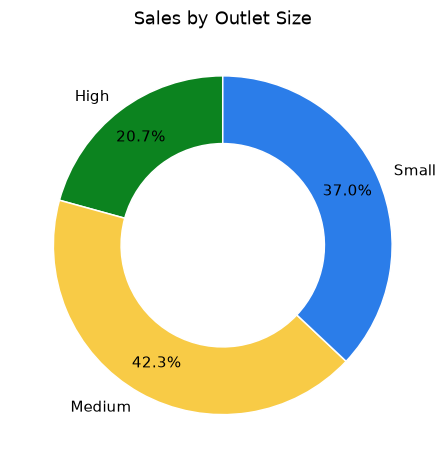

In [8]:
t = summary("Outlet Size")
display(t.style.format(fmt))
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(t["Total Sales"], labels=t.index, colors=PAL, autopct="%1.1f%%", startangle=90,
       wedgeprops=dict(width=0.4, edgecolor="white"), pctdistance=0.8)
ax.set_title("Sales by Outlet Size"); plt.show()

### 3.6 Sales by Outlet Location (funnel)
The data only has location **tiers** (no coordinates), so a funnel by tier is used rather than a geographic map.

In [9]:
%pip install -U plotly nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "vscode"

df = pd.read_csv("C:\\Users\\user\\Downloads\\Blinkit\\blinkit_data.csv", encoding="utf-8-sig")
t = (df.groupby("Outlet Location Type")["Sales"].sum()
       .sort_values(ascending=False).reset_index(name="Total Sales"))

fig = px.funnel(t, x="Total Sales", y="Outlet Location Type",
                title="Sales by Outlet Location Type",
                color_discrete_sequence=["#0c831f"])
fig.update_traces(texttemplate="$%{x:,.0f}")
fig.show()

## 4. Key insights
- **Fat content:** Low Fat contributes ~65% of sales; average sales and rating are practically identical for both types.
- **Item type:** Fruits & Vegetables and Snack Foods lead; Seafood, Breakfast and Hard Drinks are smallest.
- **Outlets:** Eight outlets sell $125-135K each; OUT010 and OUT019 are much lower.
- **Establishment year:** The 1998 outlet is the peak, the 2011 outlet the low.
- **Size / location:** Medium outlets and Tier 3 locations lead; High-size outlets and Tier 1 trail.
- **Ratings** hover around 4.0 everywhere, so sales differences come mostly from volume, not satisfaction or price.